# Model 3: Hierarchical Bayesian GAM by Product

This notebook extends Model 2 by allowing each product to have its own demand curve while still sharing information across products.

The core idea is partial pooling: product curves can differ, but they are regularised toward a shared global pattern. This is useful when each product has limited data and we do not want wildly unstable product-level curves.


- Non-linear (Good)
- Hierarchical (Good)
- Global variance (Not - Good)

## Notebook setup

The sampling defaults are intentionally smaller than the script defaults so the notebooks are easier to run interactively. Increase `DRAWS`, `TUNE`, or `CHAINS` when you want more stable final inference.


In [40]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Keep Matplotlib/ArviZ cache files inside the project environment.
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".matplotlib-cache"))

FIGURES_DIR = PROJECT_ROOT / "figures"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

# RANDOM_SEED = 123
# DRAWS = 500
# TUNE = 500
# CHAINS = 2
# TARGET_ACCEPT = 0.9
RANDOM_SEED = 123
DRAWS = 500
TUNE = 500
CHAINS = 2
TARGET_ACCEPT = 0.9
CORES = 1


In [41]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm

from utils.data_loader import load_sales_data

az.style.use("arviz-whitegrid")


In [42]:
sales_df = load_sales_data()
sales_df.head()


,product,quantity,unit_price
0,Standard iPhone Case,444,38.79
1,Standard iPhone Case,477,36.12
2,Standard iPhone Case,656,27.62
3,Standard iPhone Case,507,36.48
4,Standard iPhone Case,513,37.50


In [43]:
sales_df.info()
sales_df.describe(include="all")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197 entries, 0 to 196
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   product     197 non-null    category
 1   quantity    197 non-null    int64   
 2   unit_price  197 non-null    float64 
dtypes: category(1), float64(1), int64(1)
memory usage: 3.5 KB


,product,quantity,unit_price
count,197,197.000000,197.000000
unique,2,NaN,NaN
top,Standard iPhone Case,NaN,NaN
freq,100,NaN,NaN
mean,NaN,440.137056,46.512437
std,NaN,115.559449,14.660253
min,NaN,160.000000,18.170000
25%,NaN,368.000000,35.030000
50%,NaN,444.000000,39.400000
75%,NaN,518.000000,60.630000


A quick plot helps anchor the modeling problem. We are looking for the relationship between `unit_price` and `quantity`, while remembering that products may have different demand curves.


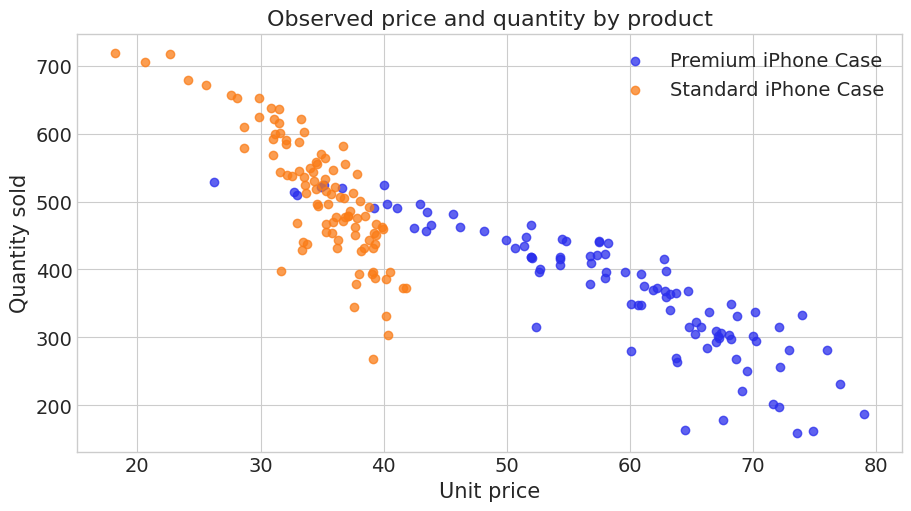

In [44]:
fig, ax = plt.subplots(figsize=(9, 5))
for product, group in sales_df.groupby("product", observed=True):
    ax.scatter(group["unit_price"], group["quantity"], alpha=0.75, label=str(product))
ax.set_xlabel("Unit price")
ax.set_ylabel("Quantity sold")
ax.set_title("Observed price and quantity by product")
ax.legend()
plt.show()


In [45]:
def standardise(values):
    values = np.asarray(values, dtype=float)
    mean = float(np.mean(values))
    std = float(np.std(values))
    if std == 0:
        raise ValueError("Cannot standardise a variable with zero variance.")
    return (values - mean) / std, mean, std


def prediction_summary(posterior_predictive, original_data, var_name="quantity_obs"):
    draws = posterior_predictive.posterior_predictive[var_name].values
    draws = draws.reshape(-1, draws.shape[-1])
    summary = pd.DataFrame({
        ".pred": np.mean(draws, axis=0),
        ".pred_lower_95": np.quantile(draws, 0.025, axis=0),
        ".pred_lower_66": np.quantile(draws, 0.17, axis=0),
        ".pred_upper_66": np.quantile(draws, 0.83, axis=0),
        ".pred_upper_95": np.quantile(draws, 0.975, axis=0),
    })
    return pd.concat([original_data.reset_index(drop=True), summary], axis=1)


def plot_predictions(predictions, title, facet=False):
    if not facet:
        plot_data = predictions.sort_values("unit_price")
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_95"].to_numpy(), plot_data[".pred_upper_95"].to_numpy(), alpha=0.20, label="95% interval")
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_66"].to_numpy(), plot_data[".pred_upper_66"].to_numpy(), alpha=0.35, label="66% interval")
        for product, group in plot_data.groupby("product", observed=True):
            ax.scatter(group["unit_price"], group["quantity"], alpha=0.70, label=str(product))
        ax.plot(plot_data["unit_price"], plot_data[".pred"], linewidth=2, color="black", label="Posterior predictive mean")
        ax.set_xlabel("Unit price")
        ax.set_ylabel("Quantity sold")
        ax.set_title(title)
        ax.legend(fontsize=8)
        plt.show()
        return

    products = list(predictions["product"].cat.categories if hasattr(predictions["product"], "cat") else sorted(predictions["product"].unique()))
    fig, axes = plt.subplots(1, len(products), figsize=(6 * len(products), 5), sharey=True)
    if len(products) == 1:
        axes = [axes]
    for ax, product in zip(axes, products):
        plot_data = predictions[predictions["product"] == product].sort_values("unit_price")
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_95"].to_numpy(), plot_data[".pred_upper_95"].to_numpy(), alpha=0.20)
        ax.fill_between(plot_data["unit_price"].to_numpy(), plot_data[".pred_lower_66"].to_numpy(), plot_data[".pred_upper_66"].to_numpy(), alpha=0.35)
        ax.scatter(plot_data["unit_price"], plot_data["quantity"], alpha=0.70)
        ax.plot(plot_data["unit_price"], plot_data[".pred"], linewidth=2, color="black")
        ax.set_title(str(product))
        ax.set_xlabel("Unit price")
    axes[0].set_ylabel("Quantity sold")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


In [46]:
from sklearn.preprocessing import SplineTransformer


## Model idea

Model 2 had one spline curve. Model 3 adds product-specific intercepts and product-specific spline deviations:

```text
quantity_i ~ Normal(mu_i, sigma)
mu_i = alpha_product[product_i] + spline_basis_i @ spline_coefs_product[product_i]
```

The product coefficients are built from a global coefficient plus a product-level deviation. The size of those deviations is learned from the data.


In [47]:
model_df = sales_df.copy()
model_df["product"] = model_df["product"].astype("category")
product_idx = model_df["product"].cat.codes.to_numpy()
product_names = list(model_df["product"].cat.categories)
n_products = len(product_names)

unit_price_raw = model_df["unit_price"].to_numpy(dtype=float)
quantity = model_df["quantity"].to_numpy(dtype=float)
unit_price_scaled, price_mean, price_std = standardise(unit_price_raw)

spline_transformer = SplineTransformer(n_knots=6, degree=3, include_bias=False)
spline_basis = spline_transformer.fit_transform(unit_price_scaled.reshape(-1, 1))
n_basis = spline_basis.shape[1]

n_products, product_names, spline_basis.shape


(2, ['Premium iPhone Case', 'Standard iPhone Case'], (197, 7))

In [ ]:
with pm.Model() as model_3:
    spline_data = pm.Data("spline_basis", spline_basis)
    product_data = pm.Data("product_idx", product_idx)

    alpha_global = pm.Normal("alpha_global", mu=float(np.mean(quantity)), sigma=float(np.std(quantity) * 2))
    alpha_product_sigma = pm.HalfNormal("alpha_product_sigma", sigma=float(np.std(quantity)))
    alpha_product_offset = pm.Normal("alpha_product_offset", mu=0, sigma=1, shape=n_products)
    alpha_product = pm.Deterministic("alpha_product", alpha_global + alpha_product_offset * alpha_product_sigma)

    spline_global = pm.Normal("spline_global", mu=0, sigma=float(np.std(quantity)), shape=n_basis)
    spline_product_sigma = pm.HalfNormal("spline_product_sigma", sigma=float(np.std(quantity)), shape=n_basis)
    spline_product_offset = pm.Normal("spline_product_offset", mu=0, sigma=1, shape=(n_products, n_basis))
    spline_product = pm.Deterministic("spline_product", spline_global + spline_product_offset * spline_product_sigma)

    sigma = pm.HalfNormal("sigma", sigma=float(np.std(quantity)))

    product_spline_coefs = spline_product[product_data]
    smooth = pm.math.sum(spline_data * product_spline_coefs, axis=1)
    mu = alpha_product[product_data] + smooth

    # key
    quantity_obs = pm.Normal("quantity_obs", mu=mu, sigma=sigma, observed=quantity)

    trace_3 = pm.sample(draws=DRAWS, tune=TUNE, chains=CHAINS, cores=CORES, target_accept=0.92, random_seed=RANDOM_SEED, return_inferencedata=True, progressbar=True,)
    ppc_3 = pm.sample_posterior_predictive(trace_3, var_names=["quantity_obs"], random_seed=RANDOM_SEED, return_inferencedata=True, progressbar=True,)


/Users/aryamathew/Documents/learn-business-datascience/hierarchical-models/bayesian_price_elasticity/.venv/lib/python3.9/site-packages/pymc/data.py:434: UserWarning: The `mutable` kwarg was not specified. Before v4.1.0 it defaulted to `pm.Data(mutable=True)`, which is equivalent to using `pm.MutableData()`. In v4.1.0 the default changed to `pm.Data(mutable=False)`, equivalent to `pm.ConstantData`. Use `pm.ConstantData`/`pm.MutableData` or pass `pm.Data(..., mutable=False/True)` to avoid this warning.
  warnings.warn(
Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (2 chains in 1 job)
NUTS: [alpha_global, alpha_product_sigma, alpha_product_offset, spline_global, spline_product_sigma, spline_product_offset, sigma]


Sampling 2 chains for 500 tune and 500 draw iterations (1_000 + 1_000 draws total) took 65 seconds.
There were 8 divergences after tuning. Increase `target_accept` or reparameterize.
We recommend running at least 4 chains for robust computation of convergence diagnostics
Sampling: [quantity_obs]


## Diagnostics

Hierarchical spline models have more parameters than the global spline. If you see divergences, try increasing `TARGET_ACCEPT`, increasing `TUNE`, or reducing the number of spline knots.


In [49]:
az.summary(trace_3, var_names=["alpha_global", "alpha_product_sigma", "spline_product_sigma", "sigma"])


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha_global,430.850,83.154,267.279,579.824,3.427,2.500,605.0,582.0,1.0
alpha_product_sigma,74.849,54.846,0.234,176.903,2.115,1.496,547.0,406.0,1.0
spline_product_sigma[0],94.895,70.169,0.095,219.379,1.967,1.391,893.0,463.0,1.0
spline_product_sigma[1],139.427,71.760,8.257,263.128,3.225,2.282,471.0,426.0,1.0
spline_product_sigma[2],79.167,63.211,0.199,196.774,2.200,1.601,767.0,695.0,1.0
spline_product_sigma[3],127.613,62.257,37.073,254.770,1.998,1.413,857.0,515.0,1.0
spline_product_sigma[4],92.719,70.611,0.524,222.573,2.326,1.645,756.0,606.0,1.0
spline_product_sigma[5],83.053,64.849,0.619,205.114,1.819,1.291,957.0,630.0,1.0
spline_product_sigma[6],110.911,74.035,1.067,241.135,2.606,1.843,654.0,598.0,1.0
sigma,46.833,2.309,42.233,51.099,0.068,0.048,1151.0,662.0,1.0


/var/folders/qm/sbby5mpx22g9cm6655g9bwcw0000gn/T/ipykernel_54633/1614049325.py:2: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


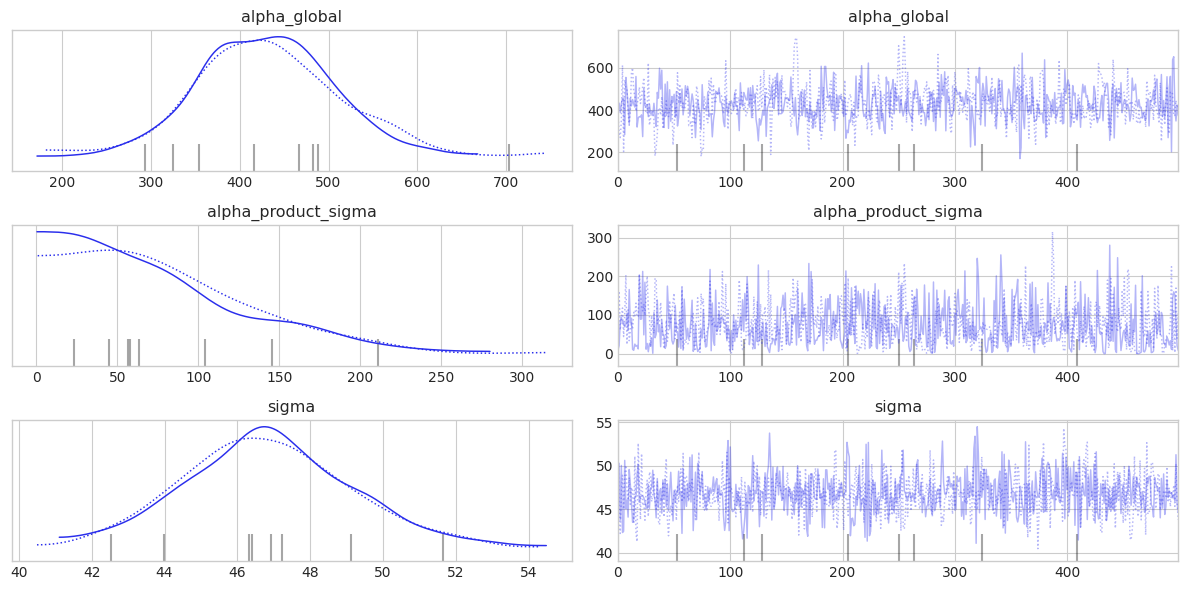

In [50]:
az.plot_trace(trace_3, var_names=["alpha_global", "alpha_product_sigma", "sigma"])
plt.tight_layout()
plt.show()


In [51]:
predictions_3 = prediction_summary(ppc_3, model_df)
predictions_3.head()


,product,quantity,unit_price,.pred,.pred_lower_95,.pred_lower_66,.pred_upper_66,.pred_upper_95
0,Standard iPhone Case,444,38.79,434.113286,340.695098,386.135058,482.700723,531.096446
1,Standard iPhone Case,477,36.12,485.345080,387.622719,438.948084,530.685969,583.800300
2,Standard iPhone Case,656,27.62,645.560421,549.455757,601.743882,691.327969,744.237469
3,Standard iPhone Case,507,36.48,479.242739,392.928087,434.074936,524.229135,572.298762
4,Standard iPhone Case,513,37.50,456.011894,365.277943,413.614688,499.309054,549.411493


/var/folders/qm/sbby5mpx22g9cm6655g9bwcw0000gn/T/ipykernel_54633/3627169406.py:53: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


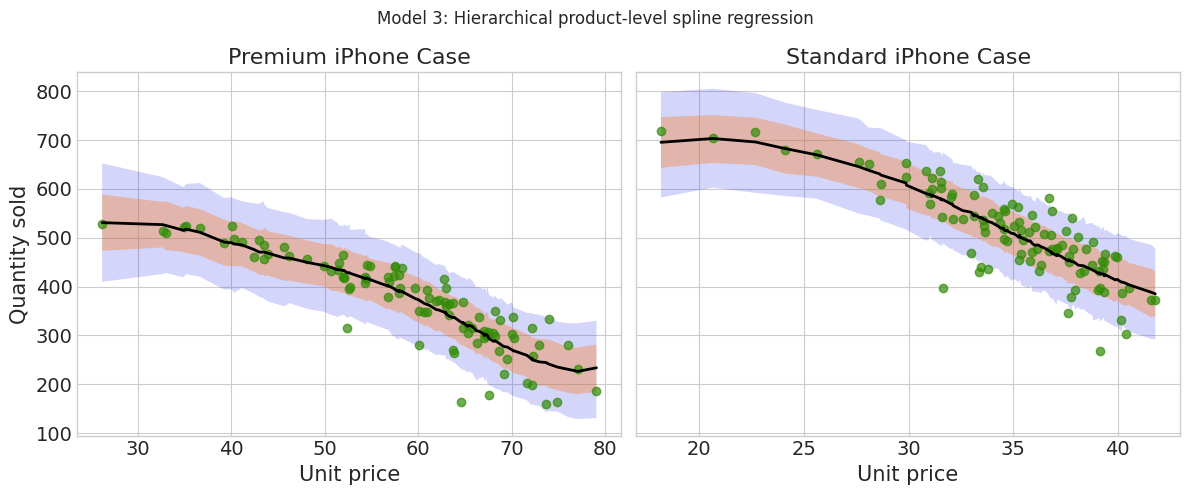

In [52]:
plot_predictions(predictions_3, "Model 3: Hierarchical product-level spline regression", facet=True)


In [53]:
# Pros: We get two different GAMs
# Cons:
# The credible intervals are pretty much the same for both. For the standard phone case it is accurate till a point, then there's more variance in the data (more risk in 60-80$ range)
# The probability isn't accurately capturing the risk - that's the problem with frequentist approaches. but also the problem of bayesian if you don't know how to model the variance

In [54]:
trace_3.to_netcdf(MODELS_DIR / "notebook_model3_hierarchical_gam_trace.nc")
predictions_3.to_csv(MODELS_DIR / "notebook_model3_hierarchical_gam_predictions.csv", index=False)
print("Saved notebook Model 3 outputs.")


Saved notebook Model 3 outputs.


## Interpretation

Model 3 is usually the first model in this sequence that matches the business problem well. It can represent different product demand curves, but it still borrows strength through the shared global curve and learned deviation scales.
